In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage

In [6]:
df=pd.read_csv("cities_r2.csv")
df.head(5)

,name_of_city,state_code,state_name,dist_code,population_total,population_male,population_female,0-6_population_total,0-6_population_male,0-6_population_female,...,literates_female,sex_ratio,child_sex_ratio,effective_literacy_rate_total,effective_literacy_rate_male,effective_literacy_rate_female,location,total_graduates,male_graduates,female_graduates
0,Abohar,3,PUNJAB,9,145238,76840,68398,15870,8587,7283,...,44972,890,848,79.86,85.49,73.59,"30.1452928,74.1993043",16287,8612,7675
1,Achalpur,27,MAHARASHTRA,7,112293,58256,54037,11810,6186,5624,...,43086,928,909,91.99,94.77,89.00,"21.257584,77.5086754",8863,5269,3594
2,Adilabad,28,ANDHRA PRADESH,1,117388,59232,58156,13103,6731,6372,...,37660,982,947,80.51,88.18,72.73,"19.0809075,79.560344",10565,6797,3768
3,Adityapur,20,JHARKHAND,24,173988,91495,82493,23042,12063,10979,...,54515,902,910,83.46,89.98,76.23,"22.7834741,86.1576889",19225,12189,7036
4,Adoni,28,ANDHRA PRADESH,21,166537,82743,83794,18406,9355,9051,...,45089,1013,968,68.38,76.58,60.33,"15.6322227,77.2728368",11902,7871,4031


In [7]:
df.dtypes

name_of_city                       object
state_code                          int64
state_name                         object
dist_code                           int64
population_total                    int64
population_male                     int64
population_female                   int64
0-6_population_total                int64
0-6_population_male                 int64
0-6_population_female               int64
literates_total                     int64
literates_male                      int64
literates_female                    int64
sex_ratio                           int64
child_sex_ratio                     int64
effective_literacy_rate_total     float64
effective_literacy_rate_male      float64
effective_literacy_rate_female    float64
location                           object
total_graduates                     int64
male_graduates                      int64
female_graduates                    int64
dtype: object

In [8]:
df=df.drop(columns=['name_of_city','state_name','location','dist_code'])
df=df.drop('state_code',axis=1)

In [9]:
df.isnull().sum()

population_total                  0
population_male                   0
population_female                 0
0-6_population_total              0
0-6_population_male               0
0-6_population_female             0
literates_total                   0
literates_male                    0
literates_female                  0
sex_ratio                         0
child_sex_ratio                   0
effective_literacy_rate_total     0
effective_literacy_rate_male      0
effective_literacy_rate_female    0
total_graduates                   0
male_graduates                    0
female_graduates                  0
dtype: int64

In [10]:
X=df

scaler=StandardScaler()

x_scaled=scaler.fit_transform(X)

0.8476563150847697
0.7404032482801951
0.28975368330349316
0.27561862037945095
0.3028962690198545
0.2965283953493163
0.2717287142445084
0.27170139412760846
0.27385822831293993
[4269.6691185509835, 3324.762210205339, 2431.5210177793283, 1969.1466904060894, 1621.1669891366528, 1461.5995127139427, 1310.966756006546, 1178.9964068665904, 1108.4868976400348]


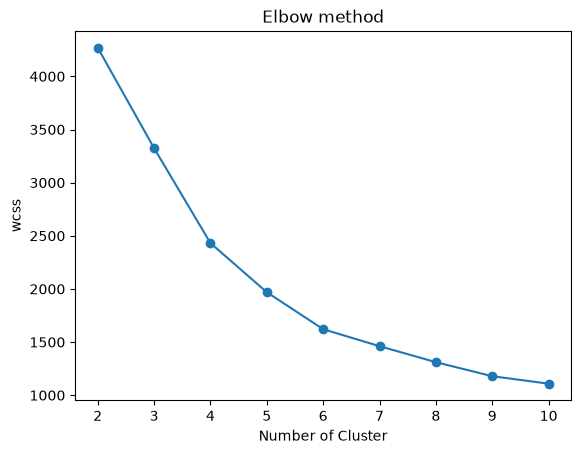

In [14]:
# clustering
from sklearn.metrics import silhouette_score
wcss=[]

for i in range(2,11):
    kmeans=KMeans(n_clusters=i,n_init=10,random_state=42)
    kmeans.fit(x_scaled)
    labels=kmeans.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)
    print(score)

    wcss.append(kmeans.inertia_)

print(wcss)

#plot graph
plt.plot(range(2,11),wcss,marker='o')
plt.title("Elbow method")
plt.xlabel("Number of Cluster")
plt.ylabel("wcss")
plt.show()

In [23]:
Kmeans=KMeans(n_clusters=1,n_init=10,random_state=42)
kmeans.fit(x_scaled)
kmeans_labels=kmeans.fit_predict(x_scaled)

print(silhouette_score(x_scaled, kmeans_labels))

0.27385822831293993


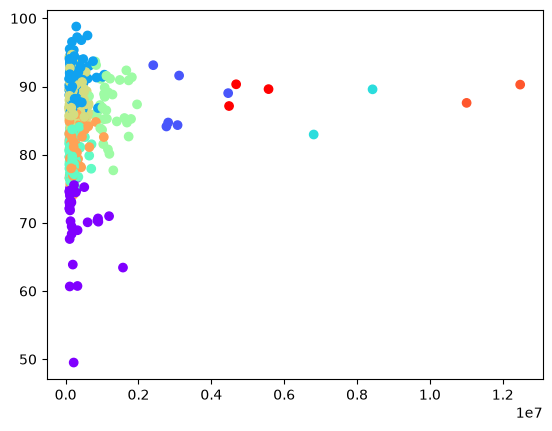

In [22]:
# plot graph here
plt.scatter(X['population_total'],X['effective_literacy_rate_total'],c=kmeans_labels,cmap="rainbow")
plt.show()

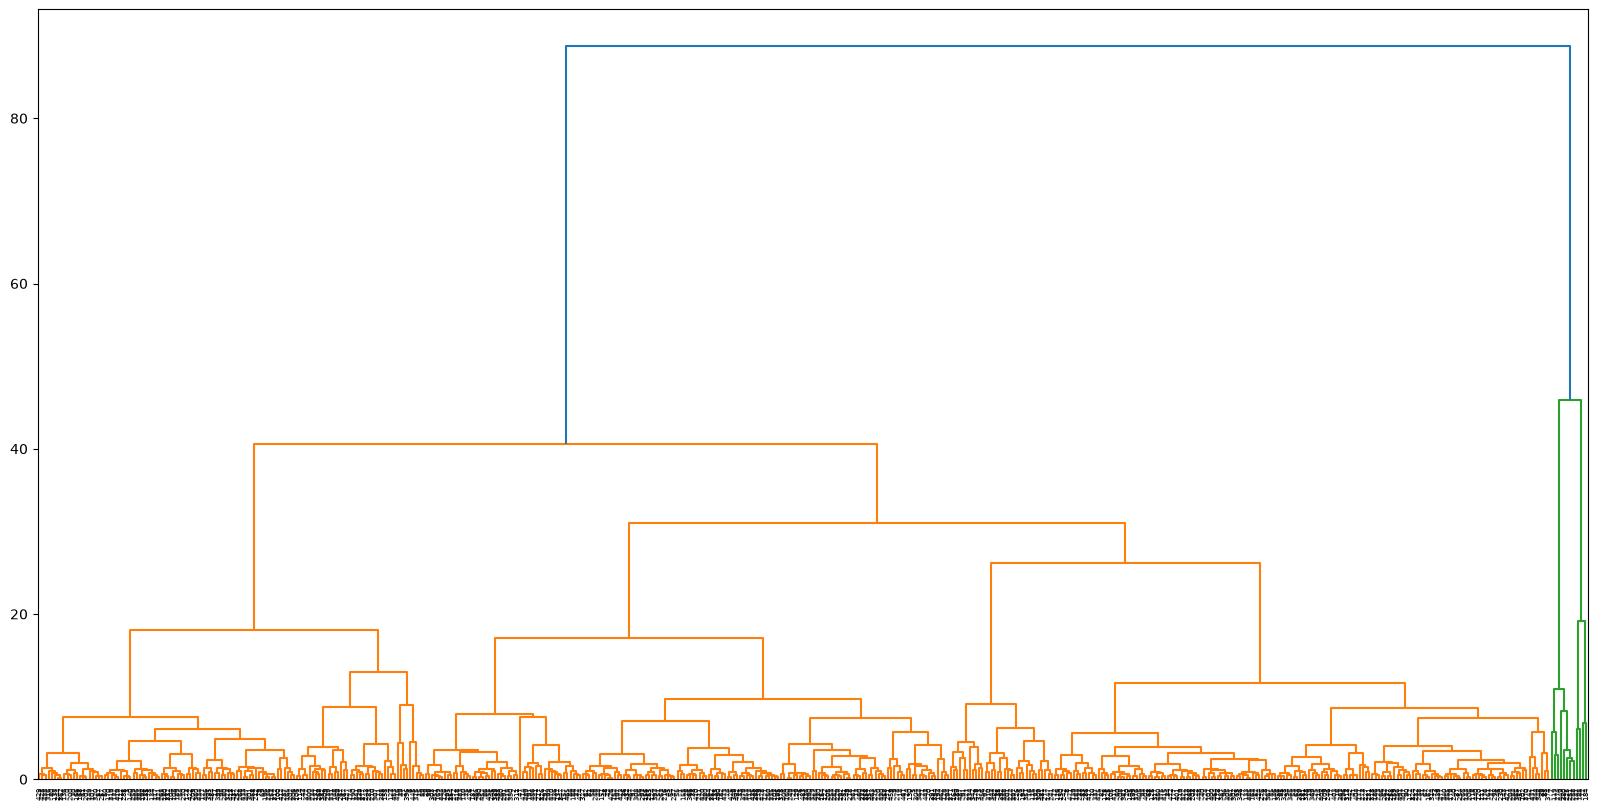

0.27385822831293993


In [25]:
# heirarchical 
# create dendrogram
linked=linkage(x_scaled,metric='euclidean',method="ward")
plt.figure(figsize=(20,10))
dendrogram(linked)
plt.show()
hc=AgglomerativeClustering(n_clusters=5)
hc_labels=hc.fit_predict(x_scaled)

print(silhouette_score(x_scaled, kmeans_labels))